In [1]:
'''
post-processing pipeline in order !!! maybe final version!!!
'''

'\npost-processing pipeline in order !!! maybe final version!!!\n'

In [3]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
#remove the lightcurves first thing, then reject 1 pixel, edges, deduplication, SNR, sobel, moving objects manual, simultaneous

In [ ]:
#maybe count the number of pixels
#count the number before matching to streaks
#then count the number matching to all streaks
#then the number that gets cut out

In [3]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [12]:
concat_band = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_with_band')

In [158]:
concat_filtered = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered3') 
#have both 

In [133]:
concat_filtered_with_rf = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered3_with_rf') 

In [ ]:
# concat_filtered_with_rf.to_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered3_with_rf') 

In [ ]:
len(concat_filtered_with_rf)

In [17]:
len(concat), len(concat_band), len(concat_filtered)

(347424, 347424, 347424)

In [159]:
concat_filtered.columns

Index(['Unnamed: 0.6', 'Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3',
       'Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'filename', 'quad',
       'type', 'row_from_nn', 'col_from_nn', 'detection_size', 'closest_x',
       'closest_y', 'Diff', 'original_cols_from_nn', 'original_rows_from_nn',
       'detection_sizes', 'modified_flag', 'original_types',
       'snr_local_brightening', 'snr_global_brightening',
       'noise_local_brightening', 'noise_global_brightening',
       'local_average_outside_brightening', 'height_brightening',
       'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 'snr_local_dimming', 'snr_global_dimming',
       'noise_local_dimming', 'noise_global_dimming',
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 'quadrant',
       'num_in_file_in_star', 'Band', 'snr_local_brightening_filtered2',
       'snr_global_brightening_filtered2', 'noise_lo

In [ ]:
#so right now we start with concat as _diffcut5_size1_dedup_snr
#lets not recalculate it for now

In [164]:
def remove_starting_edges(concat): #first 100 pixels go bye bye #which turns into 90 cause 10 already gone
    df = concat.copy()
    df["concat_index_copy"] = concat.index.values
    beginningstodrop = []
    for index in df.index.values:
        if df.loc[index, 'filename'][-5:]=='0000.':
            if df.loc[index,'quad']==1 or concat.loc[index,'quad']==2:
                if df.loc[index, 'row_from_nn']<90:
                    beginningstodrop.append(index)
            elif df.loc[index,'quad']==3 or concat.loc[index,'quad']==4:
                if df.loc[index, 'row_from_nn']+10 > 2979: #it was fine before but math is hard so im checking
                    beginningstodrop.append(index)
    df.drop(index=np.unique(beginningstodrop), inplace=True)
    return df, beginningstodrop

In [165]:
nostartingedges, beginningstodrop = remove_starting_edges(concat_filtered)

In [126]:
def original_rows_to_array(original):
    # array = np.zeros((20,20))
    cleaned = original[1:-1]
    
    # Split into rows
    rows = []
    current_row = []
    
    # Split by brackets to identify rows
    parts = cleaned.strip().split(' ')
    # print(parts)
    real = []
    for part in parts:
        if part!='':
            correct = float(part)
            real.append(correct)
    
    real = np.array(real)
    
    return np.array(real)

In [39]:
for listy in concat_filtered.loc[beginningstodrop, 'original_rows_from_nn'].values:
    for el in original_rows_to_array(listy):
        if el>90:
            if el<2969:
                print(listy)


[81.30769231 90.82352941]
[2962.66666667 2978.8        2971.        ]
[2964.8 2993.5]
[2958.         2983.35294118 2976.        ]


In [64]:
len(nostartingedges)

346902

In [46]:
# def count_real_snr(df):
#     for i, row in df.iterrows():
#         if row['snr_local_brightening']==np.NaN:
#             print("found one!")
# #just kidding...it appears that we calculated SNR for everything :0

In [47]:
def remove_sobel(concat):
    df = concat.copy()
    brightening = pd.read_csv('/home/3155/sobel_ratios') #sobels for SNR>1 candidates
    droplist = brightening[brightening['sobel_ratiocentral_point_brightening5']<=2]['index_copy'].values
    # realdroplist = droplist[droplist in df.index.values]
    realdroplist = []
    for el in droplist:
        if el in df.index.values:
            realdroplist.append(el)
    print('btw we already removed some of these: ',len(droplist)-len(realdroplist))
    df.drop(index=np.unique(realdroplist), inplace=True)
    return df
    


In [166]:
nosobel = remove_sobel(nostartingedges)

btw we already removed some of these:  1


In [89]:
len(nosobel)

345658

In [150]:
def remove_manual_sats(concat):
    satlist = np.load("/lustre/lrspec/ZTF_data/final_satlist.npy")
    moresats = np.array([195365, 291022, 163685, 326045, 272956, 306621, 22579, 
            79095,262472, 293337, 298575, 154765,181844, 272947, 329013, 
                176927, 192302, 179370, 52316, 131777, 117765, 82320, 224886, 131780])#from filtered result
    df = concat.copy()
    # realdroplist = droplist[droplist in df.index.values]
    realdroplist = []
    for el in np.hstack((satlist, moresats)):
        if el in df.index.values:
            realdroplist.append(el)
    print('btw we already removed some of these: ',len(satlist)-len(realdroplist))
    df.drop(index=np.unique(realdroplist), inplace=True)
    return df

In [91]:
# np.save("/lustre/lrspec/ZTF_data/final_satlist.npy", np.array(final_satlist))
##double checked and they all look good
#rff.inspect_df_w_stamp_color(concat.loc[final_satlist][300:], titlecol=['concat_index_copy'], imgsize=20)

In [167]:
nosats = remove_manual_sats(nosobel)

btw we already removed some of these:  84


In [152]:
len(nosats)

345345

In [163]:
nosats.columns

Index(['Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2',
       'Unnamed: 0.1', 'Unnamed: 0', 'filename', 'quad', 'type', 'row_from_nn',
       'col_from_nn', 'detection_size', 'closest_x', 'closest_y', 'Diff',
       'original_cols_from_nn', 'original_rows_from_nn', 'detection_sizes',
       'modified_flag', 'original_types', 'snr_local_brightening',
       'snr_global_brightening', 'noise_local_brightening',
       'noise_global_brightening', 'local_average_outside_brightening',
       'height_brightening', 'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 'snr_local_dimming', 'snr_global_dimming',
       'noise_local_dimming', 'noise_global_dimming',
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 'quadrant',
       'num_in_file_in_star', 'Band', 'snr_local_brightening_filtered2',
       'snr_global_brightening_filtered2', 'noise_local_brightening_filtere

In [148]:
def make_final_df(concat, local_or_global="local", filtered='', num=100):
    '''
    filtered can be _filtered2 or _f3 or just ''
    '''
    df = concat.copy()
    df["concat_index_copy"] = concat.index.values
    i
    dfs_pos = df.sort_values("snr_"+local_or_global+"_brightening"+filtered, ascending=False)[:num]
    dfs_neg = df.sort_values("snr_"+local_or_global+"_dimming"+filtered, ascending=False)[:num]
    # dfs_pos['snr'] = dfs_pos["snr_"+local_or_global+"_brightening"]
    # dfs_pos['real_type'] = np.full(num, "pos")
    # dfs_neg['snr'] = dfs_neg["snr_"+local_or_global+"_dimming"]
    # dfs_neg['real_type'] = np.full(num, "neg")
    all_df = pd.concat([dfs_pos,dfs_neg])
    final_df = all_df.sort_values("snr_"+local_or_global, ascending=False)[:num]
    print("using num pos: "+str(np.sum(final_df['real_type_'+local_or_global]=="pos")))
    return final_df, dfs_pos, dfs_neg

In [53]:
final_df, dfs_pos, dfs_neg = make_final_df(nosats)

using num pos: 57


In [136]:
final_df_big, dfs_pos, dfs_neg = make_final_df(nosats, num=300)

using num pos: 121


In [149]:
final_df_filtered, dfs_pos, dfs_neg = make_final_df(nosats, filtered='_filtered2',num=50)

using num pos: 31


In [150]:
final_df_filtered = add_rf_lightcurves(final_df_filtered)

In [151]:
np.sum(final_df_filtered['random_forest_result'])

20.0

In [138]:
np.sum(final_df_big['random_forest_result'])

195.0

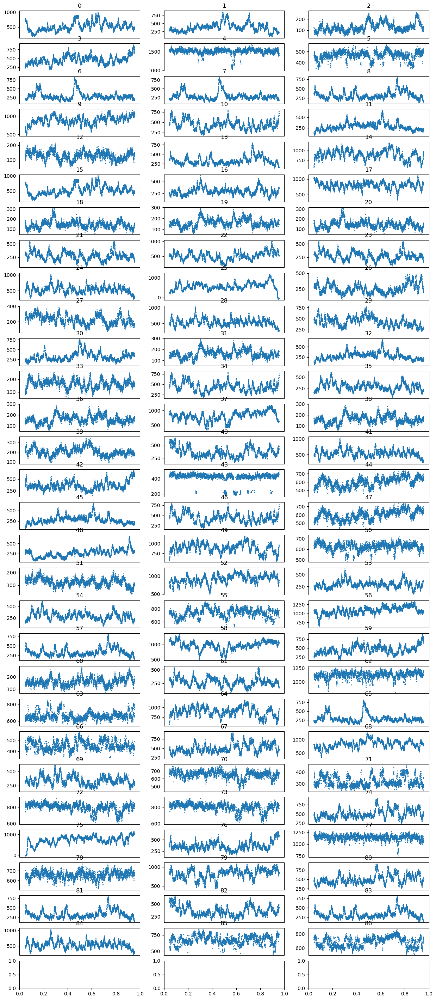

In [128]:
rff.plot_small_multiples_lcs(final_df[final_df['random_forest_result']==1], concat)

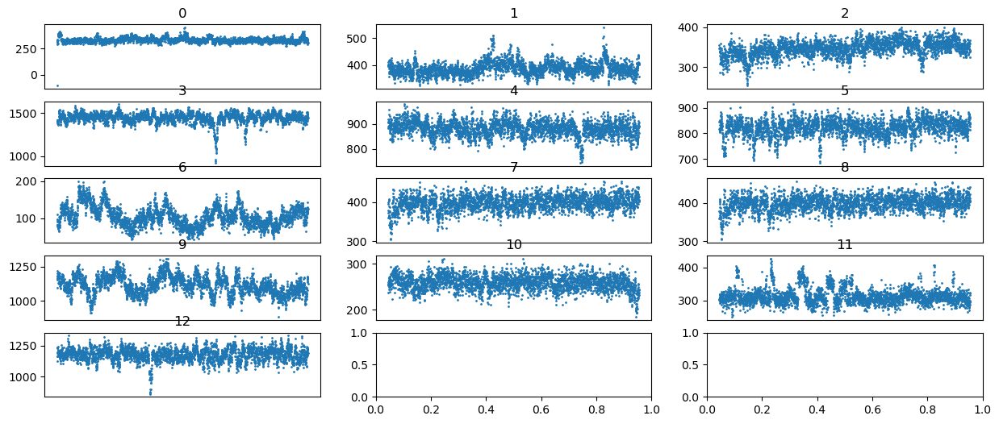

In [129]:
rff.plot_small_multiples_lcs(final_df[final_df['random_forest_result']==0], concat)

/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)


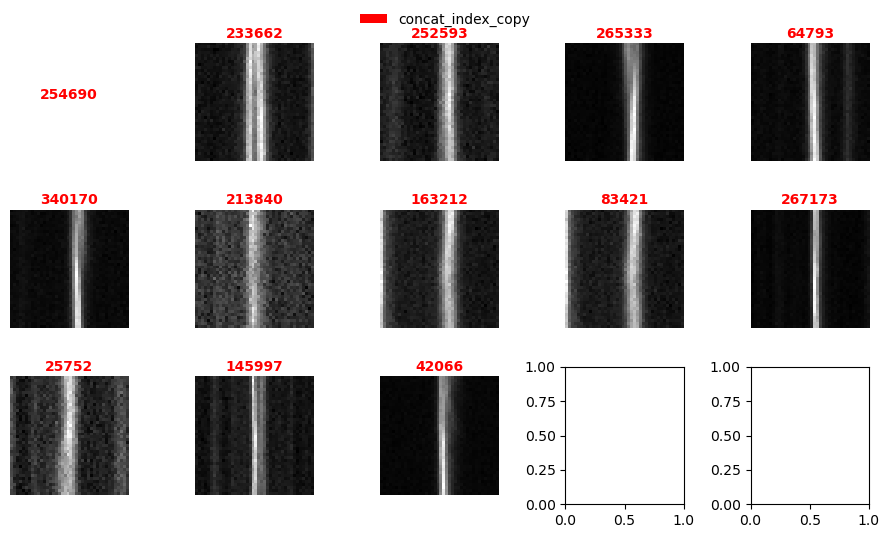

In [127]:
rff.inspect_df_w_stamp_color(final_df[final_df['random_forest_result']==0], titlecol=['concat_index_copy'], imgsize=20)

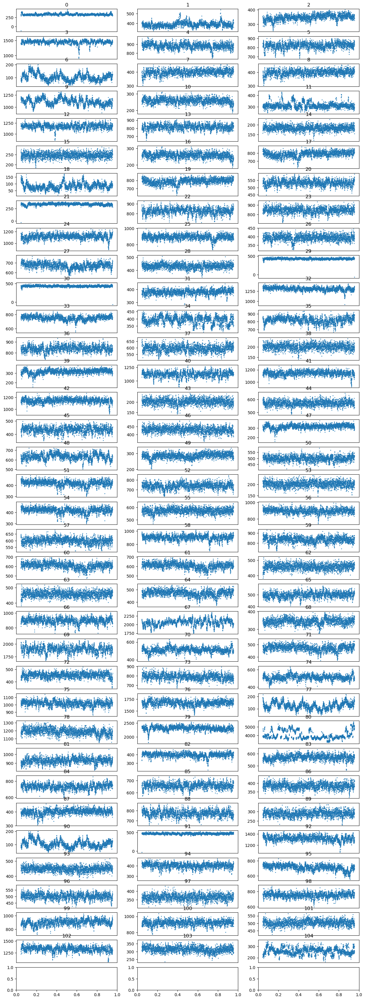

In [140]:
rff.plot_small_multiples_lcs(final_df_big[final_df_big['random_forest_result']==0], final_df_big)

/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)


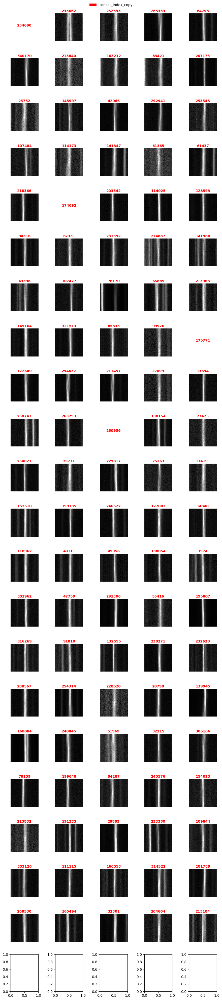

In [142]:
rff.inspect_df_w_stamp_color(final_df_big[final_df_big['random_forest_result']==0], titlecol=['concat_index_copy'], imgsize=20)

In [56]:
#last is simultaneity
#get_simultaneous_ones(index, our_cands, df_last,  snr_limit=.1, threshold=20)
#- [ ] Look if there is a candidate that is simultaneous algorithmically
# - [ ] And if yes then plot with the brightest light curves in the image, ordered by x position
# - [ ] Make sure the scale doesn’t get too compressed
concat_filtered
our_cands = final_df[final_df['random_forest_result']==0]
df_last = nosats
rff.get_simultaneous_ones(our_cands.index[0], our_cands, df_last,  snr_limit=.1, threshold=20)

(207, 80)


[254690]

In [61]:
num_simultaneous_20_p1_time = []
num_simultaneous_20_p1_space = []
for i, row in our_cands.iterrows():
    indices = rff.get_simultaneous_image_ones(i, our_cands, df_last,  snr_limit=.1, threshold=20)
    indices2 = rff.get_simultaneous_ones(i, our_cands, df_last,  snr_limit=.1, threshold=20)
    num_simultaneous_20_p1_space.append(indices)
    num_simultaneous_20_p1_time.append(indices2)
our_cands['num_simultaneous_20_p1_space']=num_simultaneous_20_p1_space
our_cands['num_simultaneous_20_p1_time']=num_simultaneous_20_p1_time

(207, 80)
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
(207, 80)
(431, 80)
9.537499999999909
(431, 80)
11.299342105263179
(627, 80)
11.5
(627, 80)
10.277777777777828
(50, 80)
(50, 80)
(106, 80)
1.916666666666515
6.762820512820326
(106, 80)
5.154761904762381
3.511904761905498
(36, 80)
(36, 80)
(134, 80)
(134, 80)
(325, 80)
8.727272727272727
8.5
6.5
(325, 80)
(330, 80)
8.727272727272727
19.5
8.5
6.5
(330, 80)
(51, 80)
(51, 80)
(513, 80)
10.54166666666697
(513, 80)
2.08771929824573
8.33333333333374
19.261904761904134
11.666666666666544
(136, 80)
9.571428571428555
(136, 80)
(81, 80)
7.227272727272748
8.727272727272748
10.227272727272748
(81, 80)


/tmp/ipykernel_45398/168619763.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_20_p1_space']=num_simultaneous_20_p1_space
/tmp/ipykernel_45398/168619763.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_20_p1_time']=num_simultaneous_20_p1_time


In [63]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [64]:
num_simultaneous_10_p1_time = []
num_simultaneous_10_p1_space = []
for i, row in our_cands.iterrows():
    indices = rff.get_simultaneous_image_ones(i, our_cands, df_last,  snr_limit=.1, threshold=10)
    indices2 = rff.get_simultaneous_ones(i, our_cands, df_last,  snr_limit=.1, threshold=10)
    num_simultaneous_10_p1_space.append(indices)
    num_simultaneous_10_p1_time.append(indices2)
our_cands['num_simultaneous_10_p1_space']=num_simultaneous_10_p1_space
our_cands['num_simultaneous_10_p1_time']=num_simultaneous_10_p1_time

/tmp/ipykernel_45398/1374439462.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_10_p1_space']=num_simultaneous_10_p1_space
/tmp/ipykernel_45398/1374439462.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_10_p1_time']=num_simultaneous_10_p1_time


In [123]:
our_cands

,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,...,real_type_global,distance_from_start,concat_index_copy,snr,real_type,random_forest_result,num_simultaneous_20_p1_space,num_simultaneous_20_p1_time,num_simultaneous_10_p1_space,num_simultaneous_10_p1_time
254690,254690,254690,254690,254690,254690,24,15,ztf_20221020157697_000640_zi_c01_x_0021.,2,pos,...,pos,1691.000000,254690,3.757073,pos,0.0,"[254690, 254666, 254667, 254670, 254671, 25467...",[254690],"[254690, 254666, 254667, 254670, 254671, 25467...",[254690]
233662,233662,233662,233662,233662,233662,31,200,ztf_20221020148032_000686_zg_c01_x_0027.,1,both,...,pos,124.562500,233662,3.601686,pos,0.0,"[233662, 233698]","[233662, 233759]","[233662, 233698]",[233662]
252593,252593,252593,252593,252593,252593,31,34,ztf_20221020163819_000640_zg_c16_x_0009.,1,pos,...,neg,1540.500000,252593,2.947931,neg,0.0,"[252593, 252714]","[252593, 252624]",[252593],[252593]
265333,265333,265333,265333,265333,265333,3,4,ztf_20221020297847_000449_zr_c09_x_0013.,2,pos,...,neg,-1456.500000,265333,2.732394,neg,0.0,[265333],[265333],[265333],[265333]
64793,64793,64793,64793,64793,64793,9,43,ztf_20221020163819_000640_zg_c14_x_0011.,4,pos,...,neg,-522.916667,64793,2.675960,neg,0.0,"[64793, 64787, 64821]","[64793, 64785, 64810]","[64793, 64787, 64821]","[64793, 64785, 64810]"
340170,340170,340170,340170,340170,340170,0,0,ztf_20221020294271_000449_zr_c14_x_0016.,3,pos,...,neg,2764.500000,340170,2.645553,neg,0.0,[340170],[340170],[340170],[340170]
213840,213840,213840,213840,213840,213840,26,81,ztf_20221020148032_000686_zg_c07_x_0015.,1,neg,...,pos,-2153.714286,213840,2.635696,pos,0.0,[213840],[213840],[213840],[213840]
163212,163212,163212,163212,163212,163212,30,2,ztf_20221020148032_000686_zg_c09_x_0028.,2,pos,...,neg,726.000000,163212,2.505133,neg,0.0,"[163212, 163198, 163216, 163242]",[163212],"[163212, 163198, 163216, 163242]",[163212]
83421,83421,83421,83421,83421,83421,32,2,ztf_20221020148032_000686_zg_c09_x_0029.,2,pos,...,neg,726.000000,83421,2.470651,neg,0.0,"[83421, 83403, 83404, 83425, 83451]",[83421],"[83421, 83403, 83425, 83451]",[83421]
267173,267173,267173,267173,267173,267173,0,0,ztf_20221020141806_000686_zi_c14_x_0027.,1,pos,...,neg,1631.750000,267173,2.228326,neg,0.0,[267173],[267173],[267173],[267173]


In [69]:
df_last

,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,concat_index_copy
0,0,0,0,0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,...,-356.194423,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0
1,1,1,1,1,1,1,3,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,...,-472.117198,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,1
2,2,2,2,2,2,2,4,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,...,-117.115640,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,2
3,3,3,3,3,3,3,6,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,...,-680.929089,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,3
4,4,4,4,4,4,4,7,ztf_20221020141806_000686_zi_c11_x_0017.,4,both,...,-279.760163,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,49,77,ztf_20221020157697_000640_zi_c05_x_0024.,3,neg,...,-198.335604,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,347419
347420,347420,347420,347420,347420,347420,50,34,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,...,-89.109350,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,347420
347421,347421,347421,347421,347421,347421,51,39,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,...,-34.856257,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,347421
347422,347422,347422,347422,347422,347422,0,0,ztf_20221020294271_000449_zr_c04_x_0003.,1,pos,...,-709.111444,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,347422


[254690]
[233662, 233759]


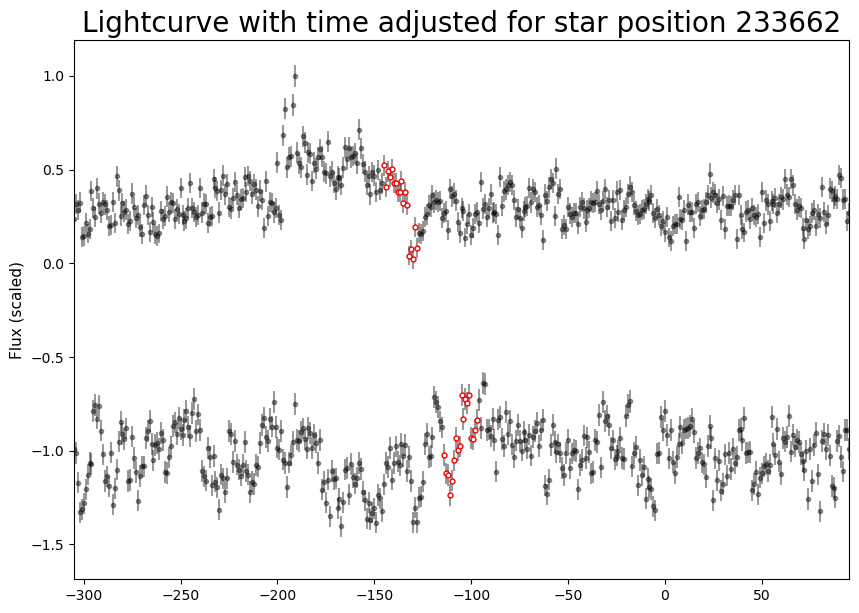

[252593, 252624]


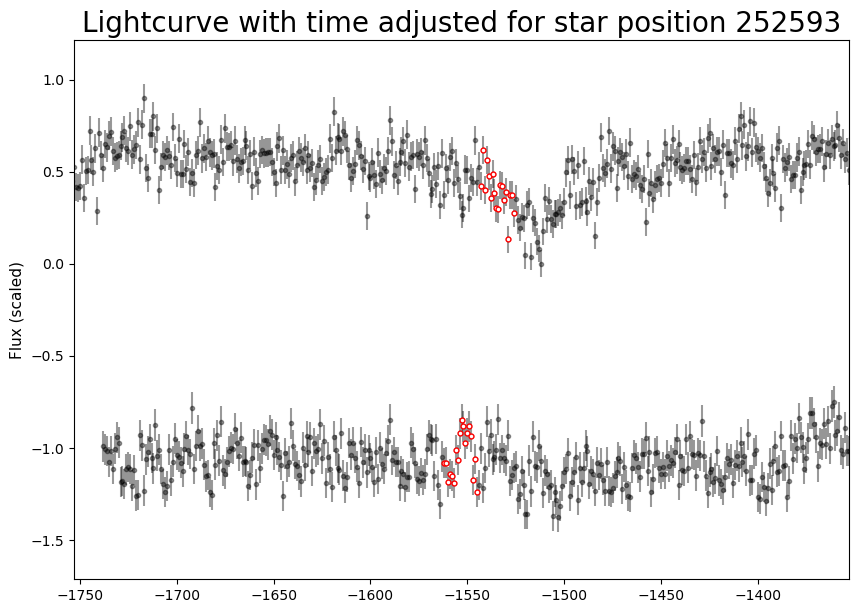

[265333]
[64793, 64785, 64810]


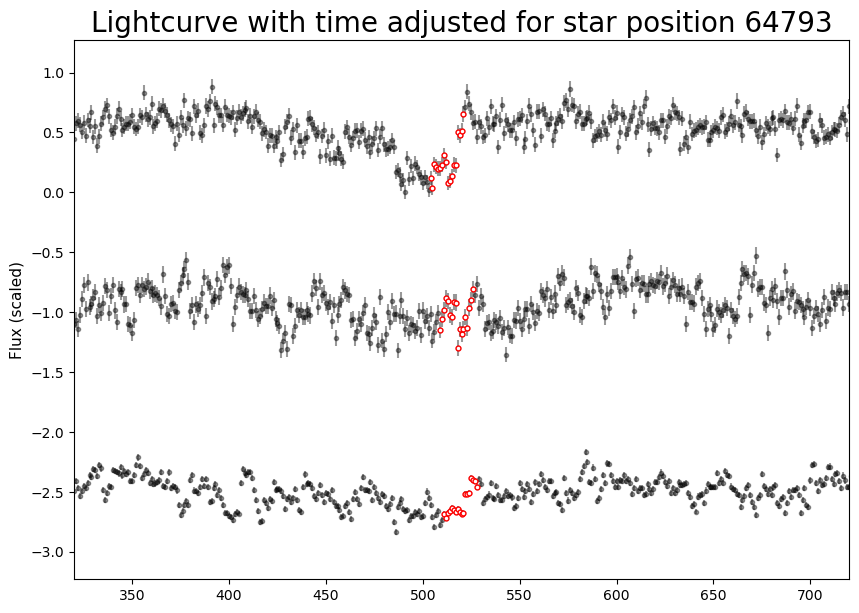

[340170]
[213840]
[163212]
[83421]
[267173]
[25752, 25760, 25817, 25880, 25899]


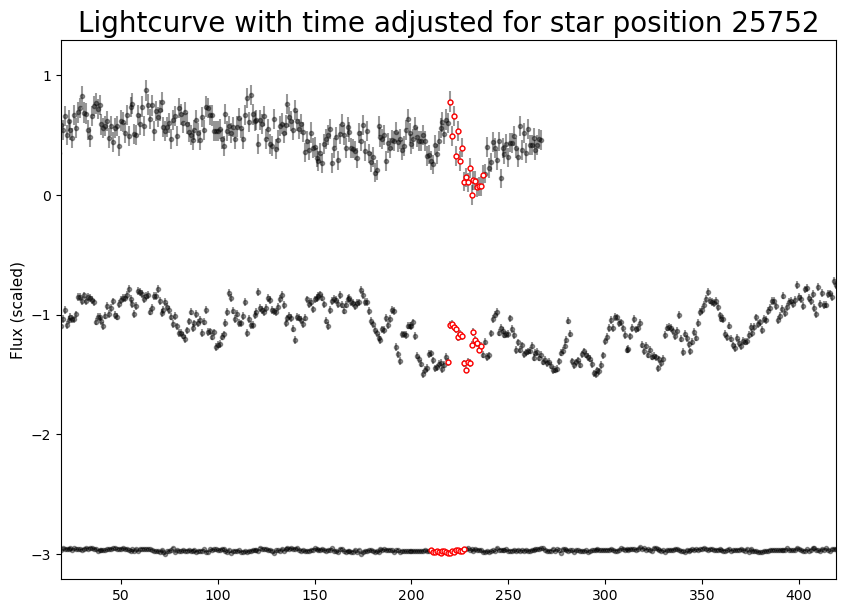

[145997]
[42066]


In [71]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_time'] #space
    print(indices)
    if len(indices)==2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], df=df_last, zoom=200)
        plt.show()
    if len(indices)>2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], indices[2],df=df_last, zoom=200)
        plt.show()

[254690]
[233662]
[252593]
[265333]
[64793, 64785, 64810]


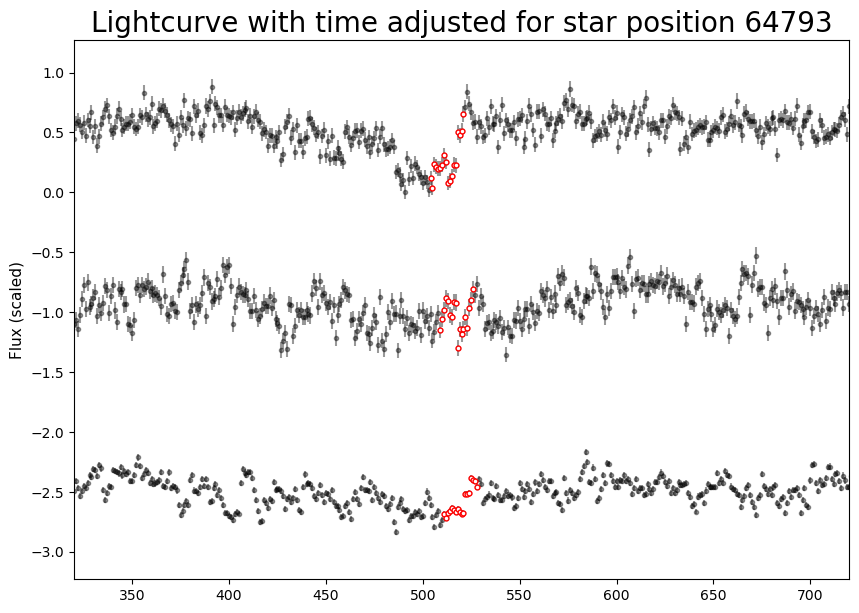

[340170]
[213840]
[163212]
[83421]
[267173]
[25752, 25760, 25817]


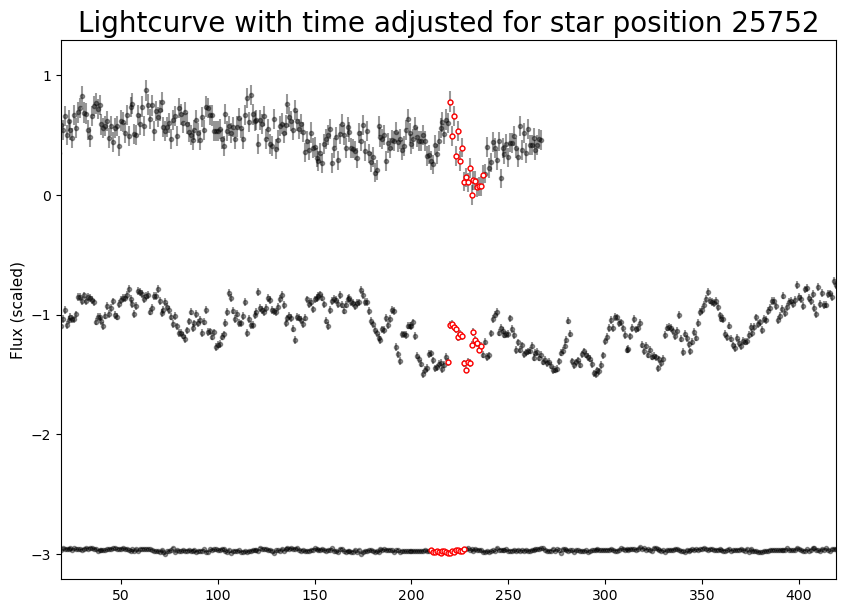

[145997]
[42066]


In [72]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_10_p1_time'] #space
    print(indices)
    if len(indices)==2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], df=df_last, zoom=200)
        plt.show()
    if len(indices)>2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], indices[2],df=df_last, zoom=200)
        plt.show()

In [87]:
lc_list, to_subtract = make_brightest_lcs_array(25752, our_cands)

In [90]:
np.shape(lc_list)

(10, 3080)

In [124]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

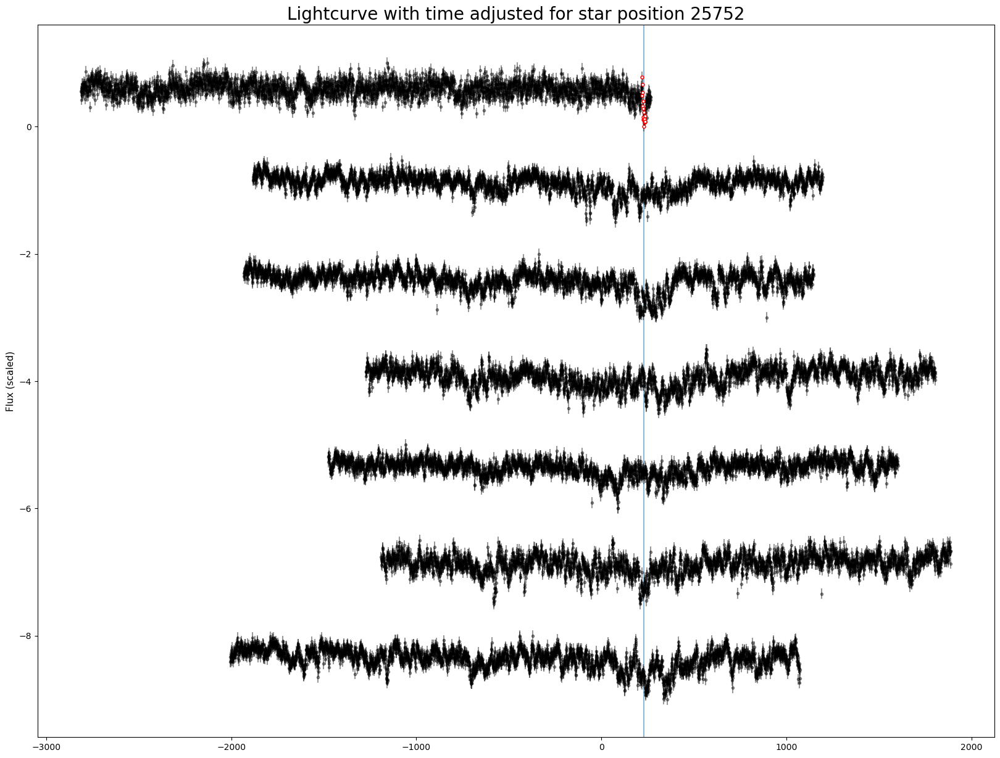

In [125]:
rff.plot_lcs_from_file(25752, our_cands)

[254690]
[233662]
[252593]
[265333]
[64793, 64785, 64810]


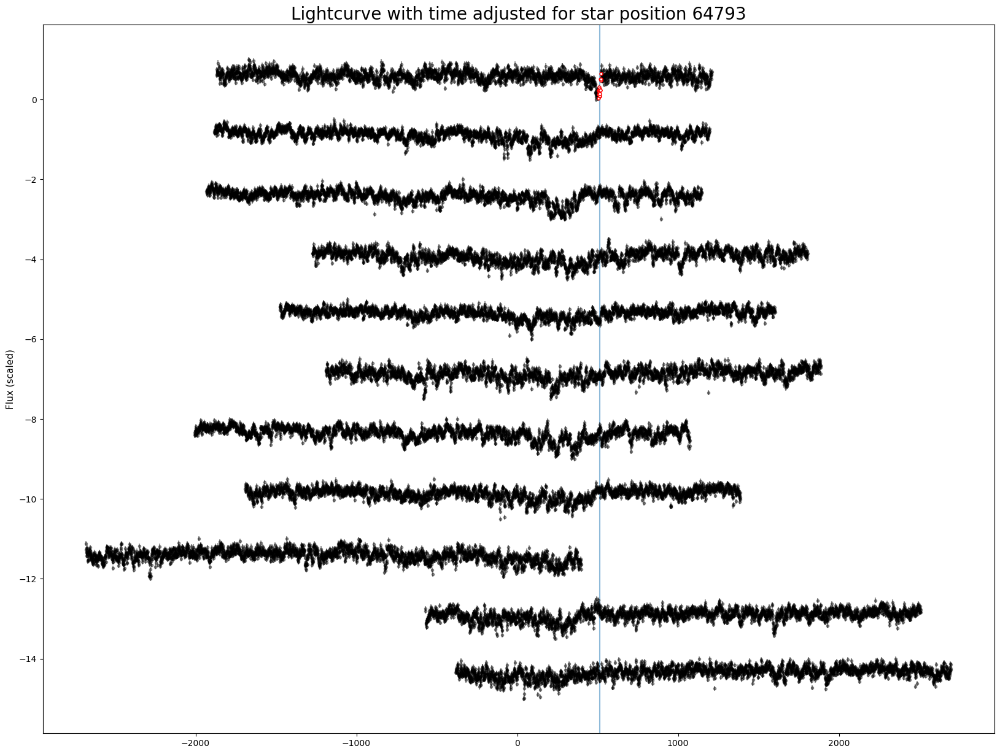

[340170]
[213840]
[163212]
[83421]
[267173]
[25752, 25760, 25817]


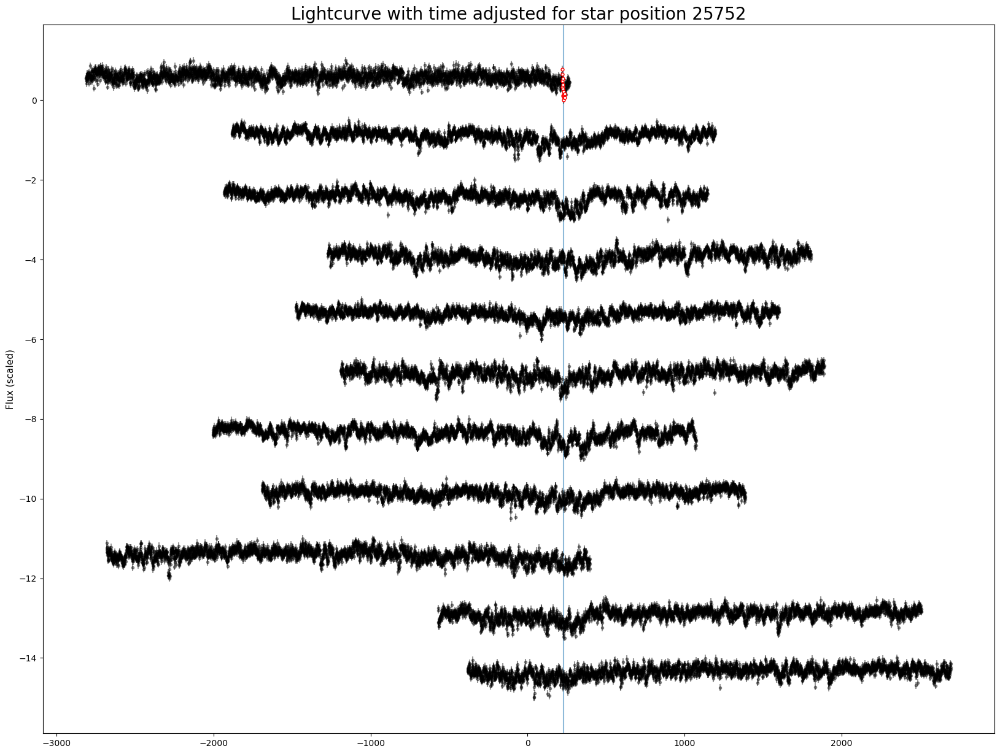

[145997]
[42066]


In [109]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_10_p1_time'] #space
    print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_from_file(i, our_cands)
        plt.show()


[254690]
[233662, 233759]


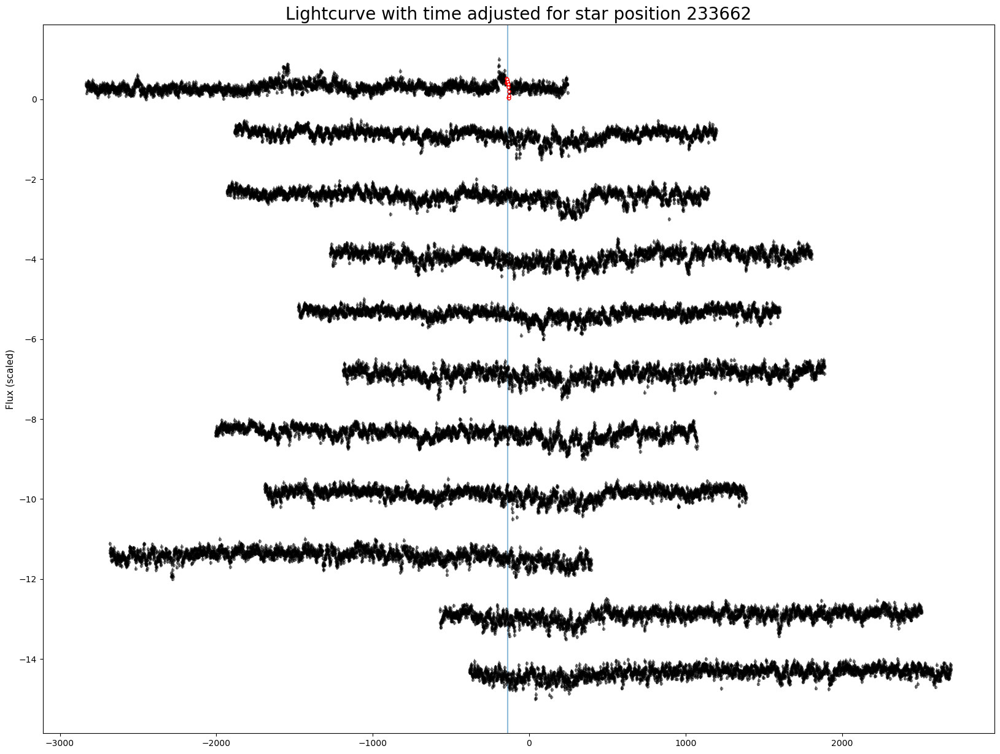

[252593, 252624]


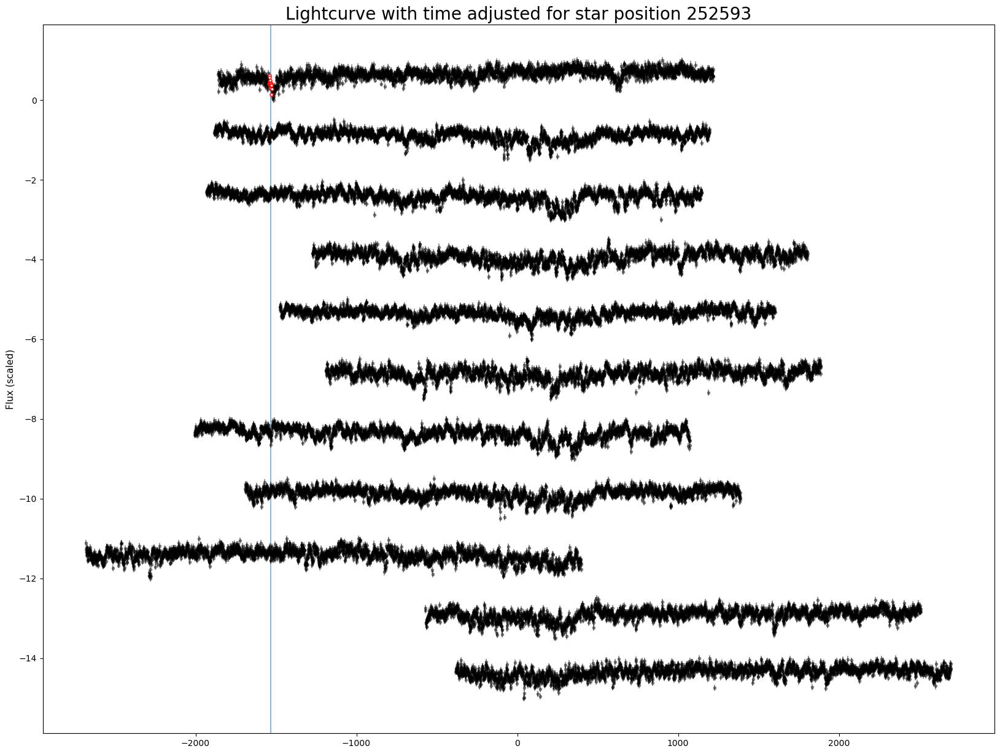

[265333]
[64793, 64785, 64810]


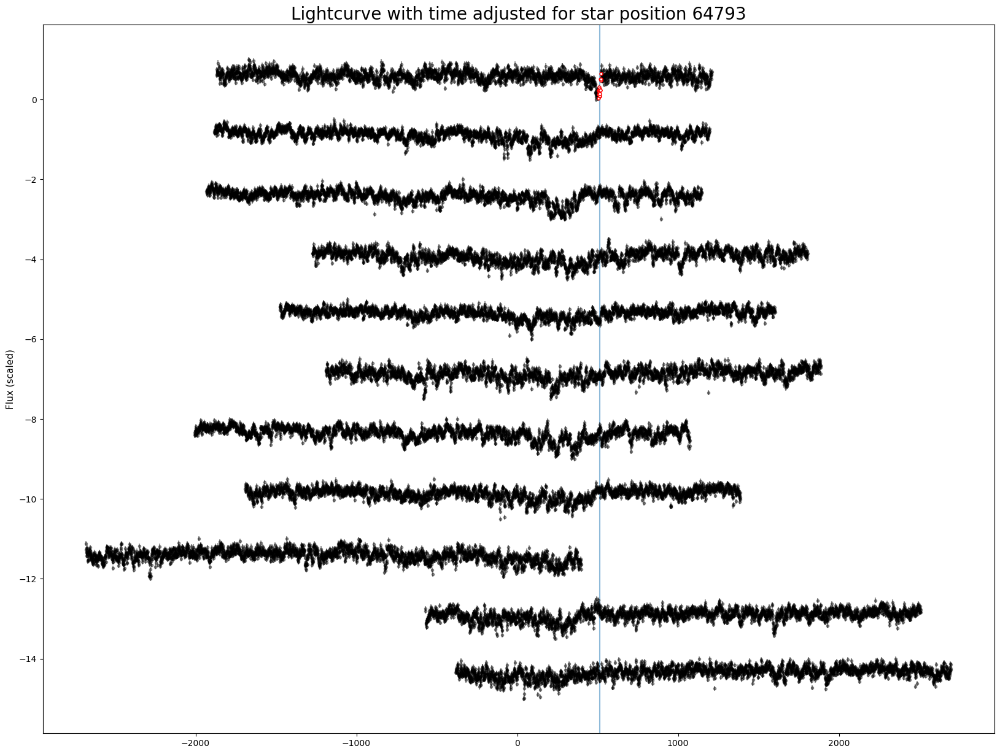

[340170]
[213840]
[163212]
[83421]
[267173]
[25752, 25760, 25817, 25880, 25899]


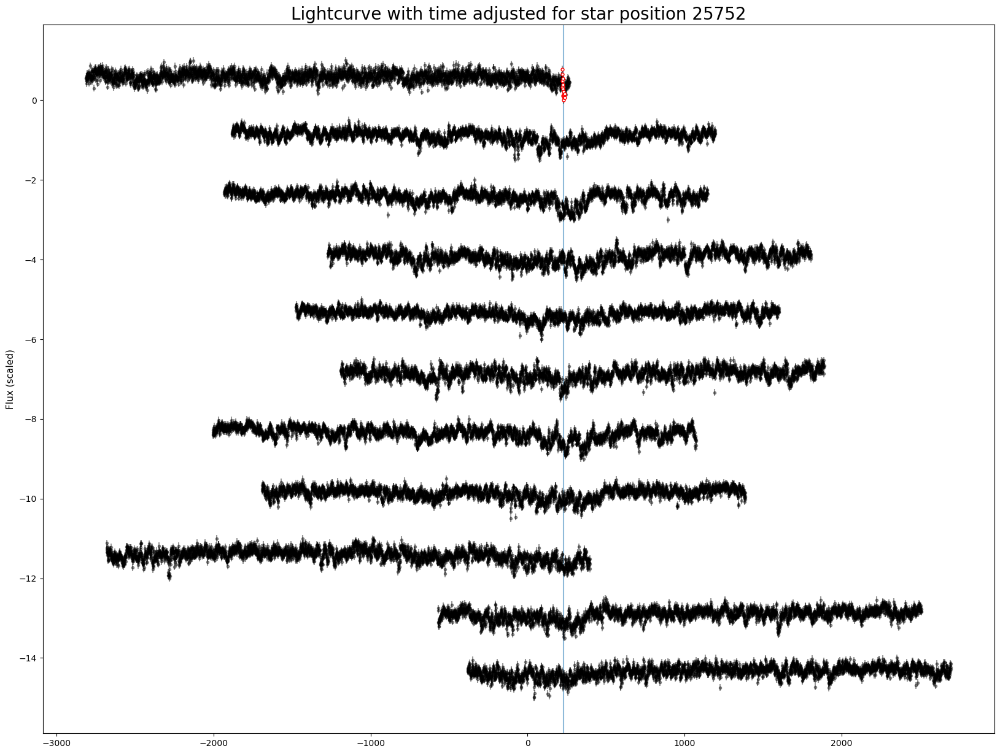

[145997]
[42066]


In [114]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_time'] #space
    print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_from_file(i, our_cands)
        plt.show()

[254690, 254666, 254667, 254670, 254671, 254672, 254673, 254674, 254675, 254678, 254679, 254680, 254684, 254688, 254691, 254692, 254693, 254694]


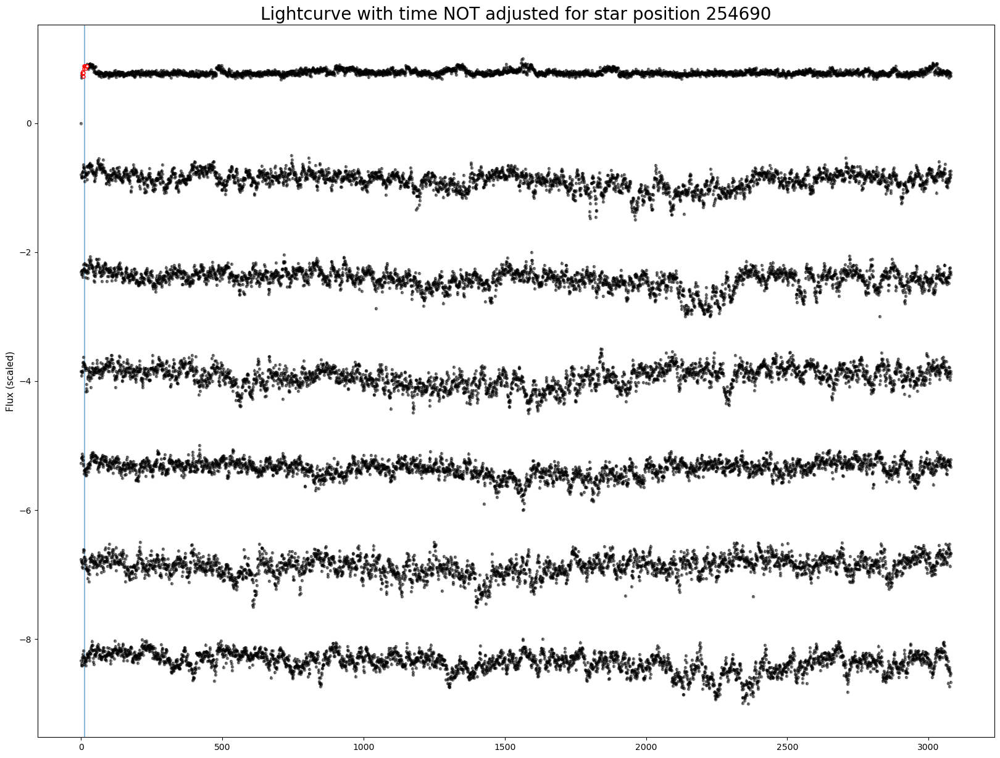

[233662, 233698]


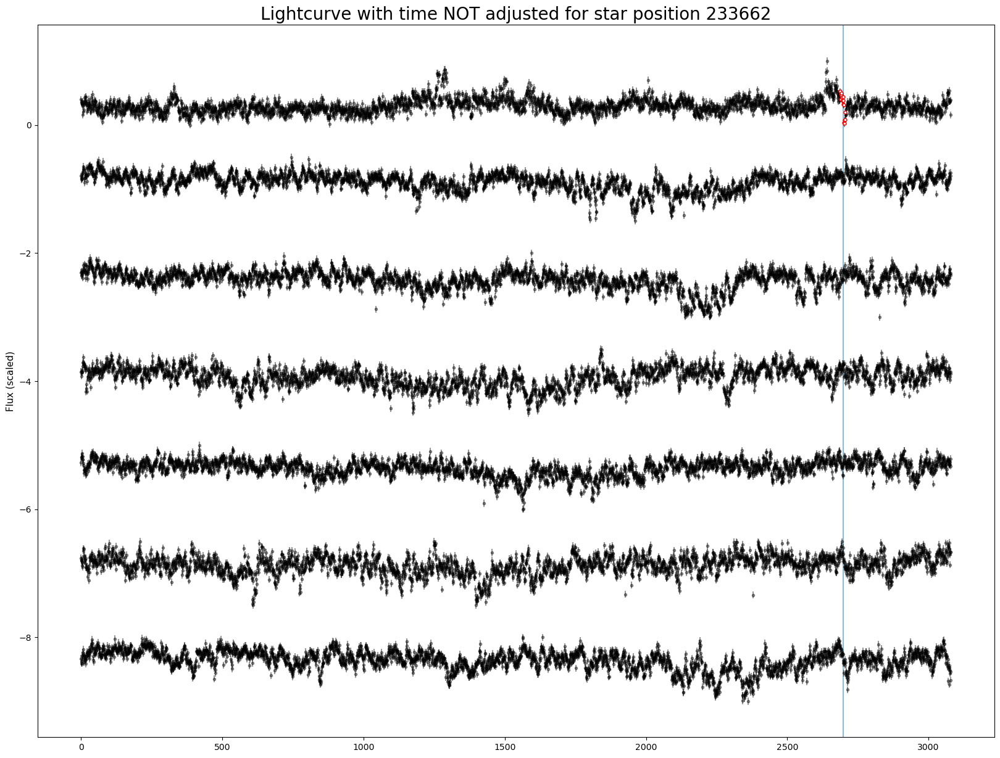

[252593, 252714]


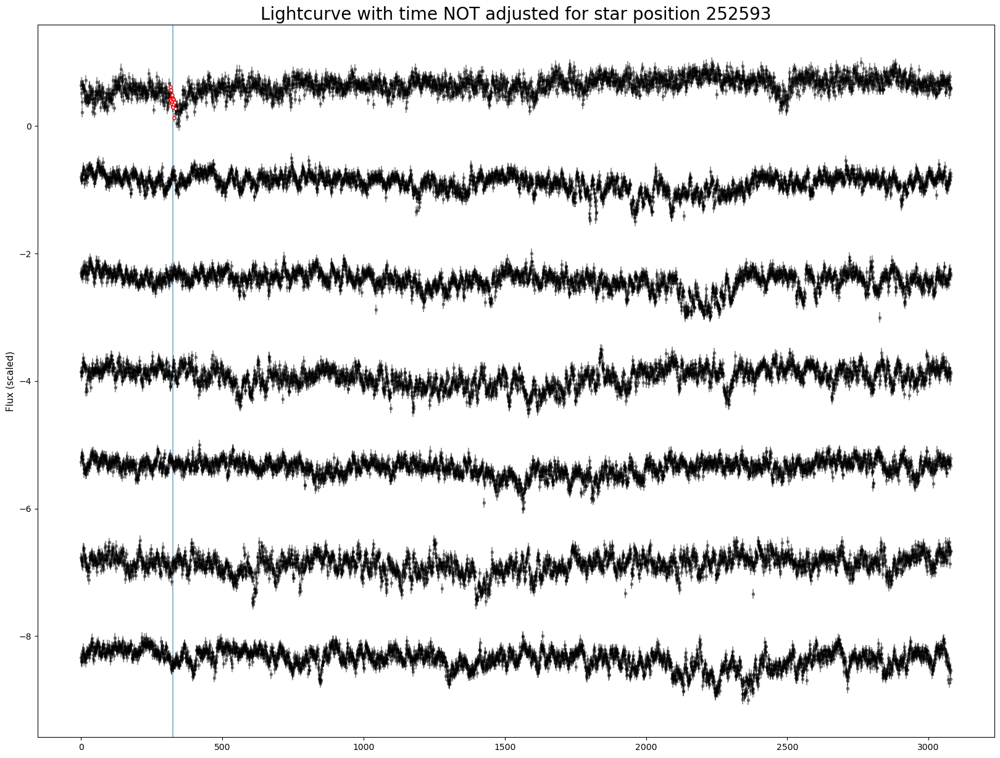

[265333]
[64793, 64787, 64821]


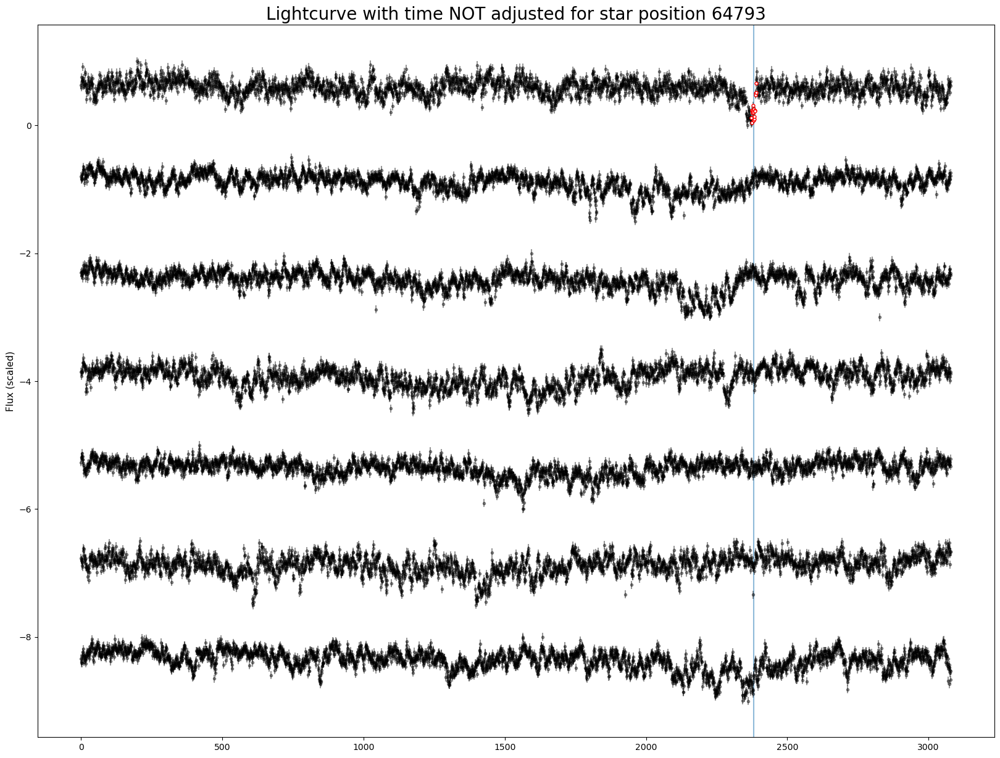

[340170]
[213840]
[163212, 163198, 163216, 163242]


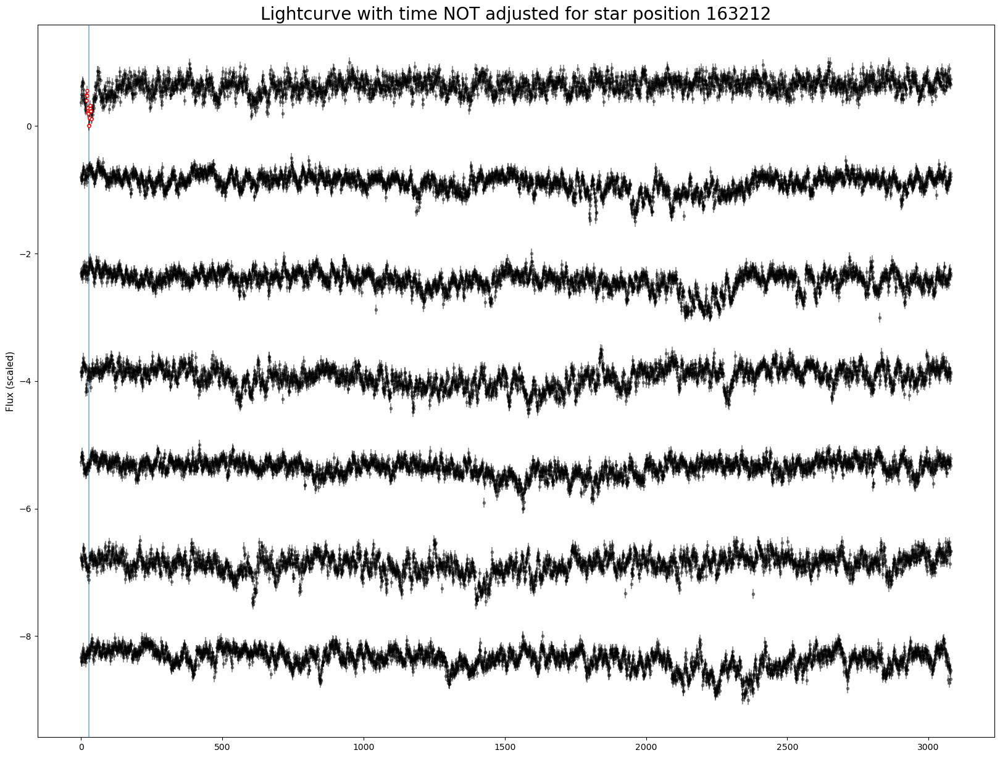

[83421, 83403, 83404, 83425, 83451]


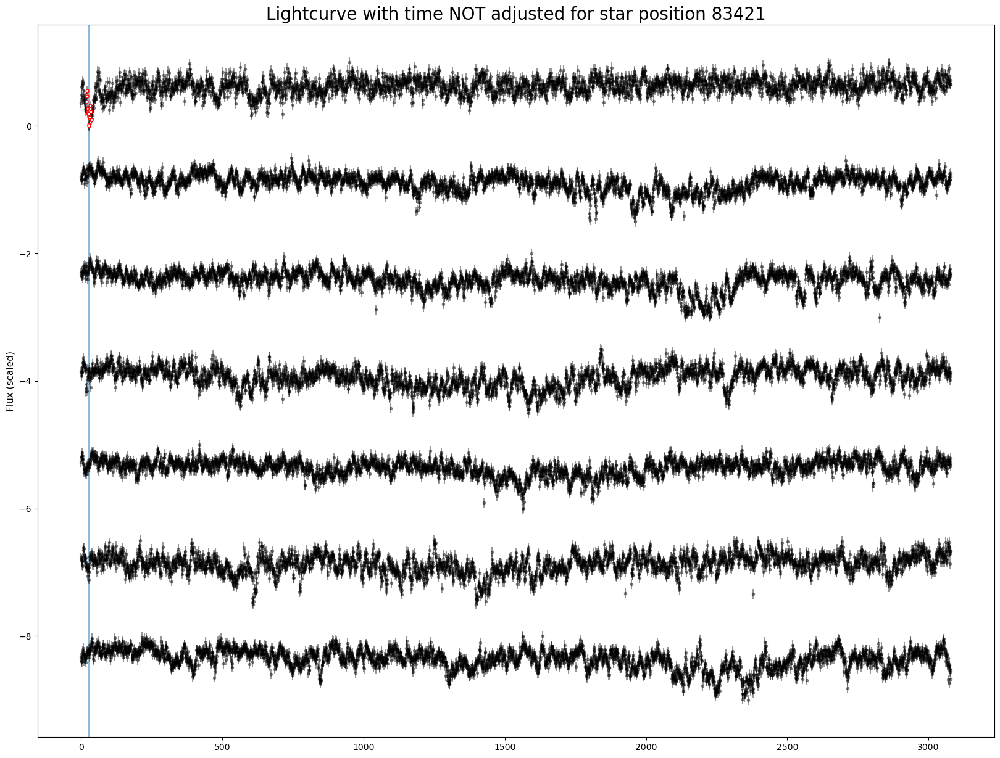

[267173]
[25752, 25894]


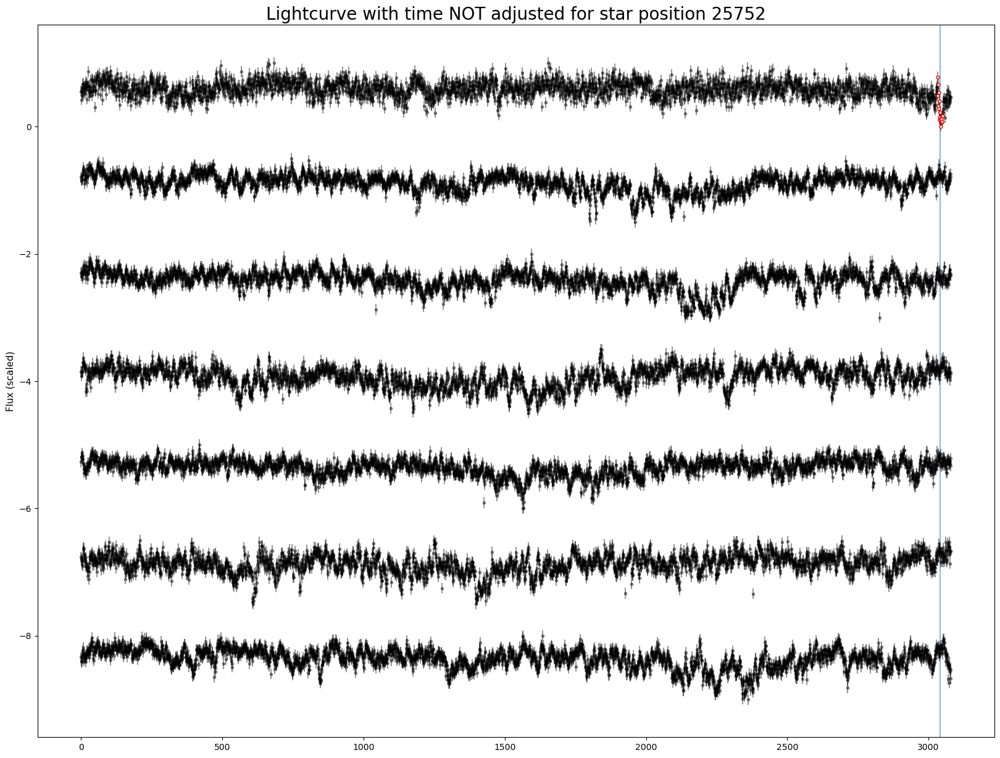

[145997, 145994]


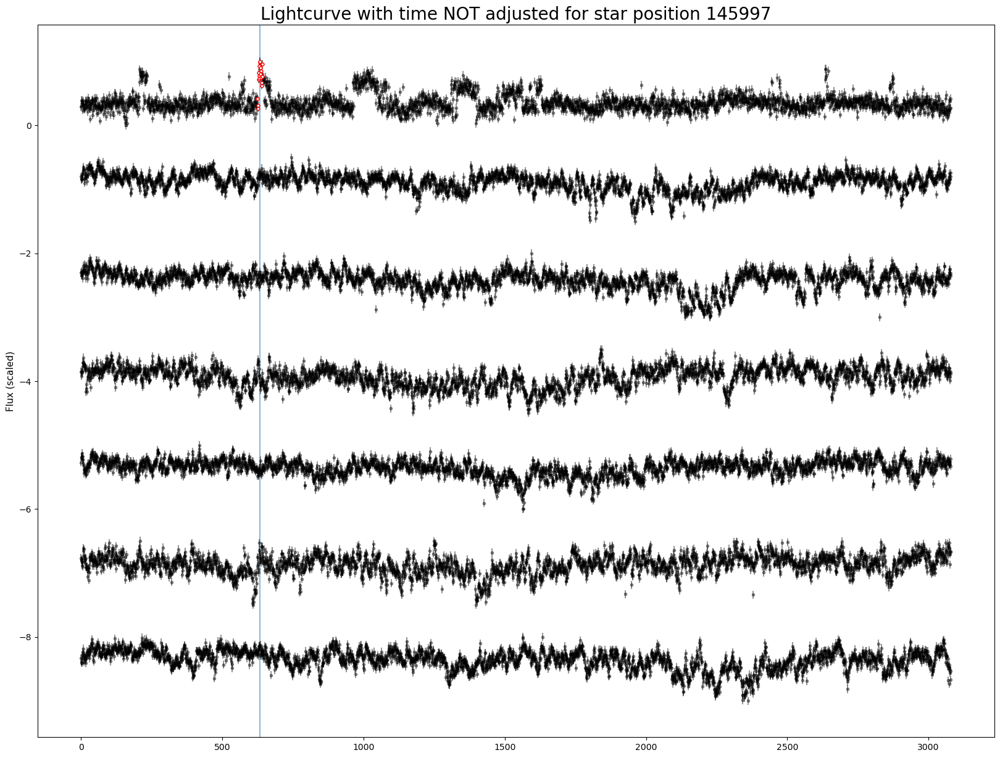

[42066, 42059, 42083, 42106]


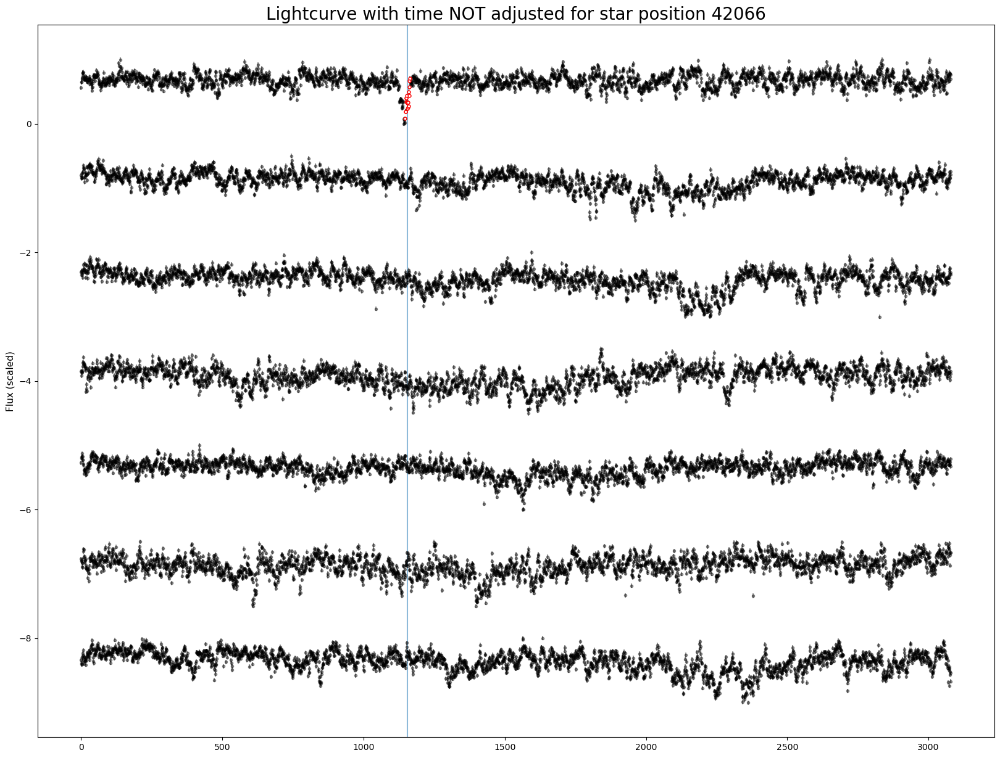

In [119]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_space'] #space
    print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_from_file(i, our_cands, time_adjusted=False)
        plt.show()

In [168]:
df = nosats.copy()

In [170]:
df['diff_brightening_local'] = df['snr_local_brightening']-df['snr_local_brightening_filtered2']

In [169]:
df.columns

Index(['Unnamed: 0.6', 'Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3',
       'Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'filename', 'quad',
       'type', 'row_from_nn', 'col_from_nn', 'detection_size', 'closest_x',
       'closest_y', 'Diff', 'original_cols_from_nn', 'original_rows_from_nn',
       'detection_sizes', 'modified_flag', 'original_types',
       'snr_local_brightening', 'snr_global_brightening',
       'noise_local_brightening', 'noise_global_brightening',
       'local_average_outside_brightening', 'height_brightening',
       'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 'snr_local_dimming', 'snr_global_dimming',
       'noise_local_dimming', 'noise_global_dimming',
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 'quadrant',
       'num_in_file_in_star', 'Band', 'snr_local_brightening_filtered2',
       'snr_global_brightening_filtered2', 'noise_lo

In [172]:
df

,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,...,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,concat_index_copy,diff_brightening_local
43719,43719,43719,43719,43719,43719,22,57,ztf_20221020148032_000686_zg_c07_x_0011.,1,pos,...,3.0,14.702464,2838.0,4.221054,2.607499,pos,pos,-2745.750000,43719,4.373777
299239,299239,299239,299239,299239,299239,47,75,ztf_20221020141806_000686_zi_c14_x_0014.,4,both,...,1.0,5.039473,2994.0,5.053696,0.959793,pos,pos,-2230.789474,299239,4.243766
254690,254690,254690,254690,254690,254690,24,15,ztf_20221020157697_000640_zi_c01_x_0021.,2,pos,...,2.0,6.845792,-10.0,3.757073,2.323363,pos,pos,1691.000000,254690,4.162979
69095,69095,69095,69095,69095,69095,53,84,ztf_20221020141806_000686_zi_c14_x_0006.,4,pos,...,7.0,28.197722,2999.0,4.180017,1.690602,pos,pos,-2237.888889,69095,3.999475
345520,345520,345520,345520,345520,345520,48,86,ztf_20221020141806_000686_zi_c14_x_0005.,4,neg,...,3.0,11.932270,70.0,5.174970,1.198552,pos,pos,689.916667,345520,3.980530
33145,33145,33145,33145,33145,33145,16,33,ztf_20221020141806_000686_zi_c14_x_0017.,4,both,...,6.0,29.721217,1461.0,3.838951,2.925893,pos,pos,-699.909524,33145,3.594322
33139,33139,33139,33139,33139,33139,10,8,ztf_20221020141806_000686_zi_c14_x_0017.,4,pos,...,5.0,23.443257,369.0,3.775091,1.896061,pos,pos,393.333333,33139,3.388466
233662,233662,233662,233662,233662,233662,31,200,ztf_20221020148032_000686_zg_c01_x_0027.,1,both,...,3.0,21.063875,2703.0,3.601686,2.535954,pos,pos,124.562500,233662,3.120755
187635,187635,187635,187635,187635,187635,14,14,ztf_20221020141806_000686_zi_c14_x_0019.,4,pos,...,6.0,21.551253,460.0,3.140651,0.995294,pos,pos,286.727273,187635,2.961127
167383,167383,167383,167383,167383,167383,23,27,ztf_20221020141806_000686_zi_c14_x_0001.,4,both,...,4.0,25.590329,677.0,2.760599,1.628011,pos,pos,83.885417,167383,2.668701


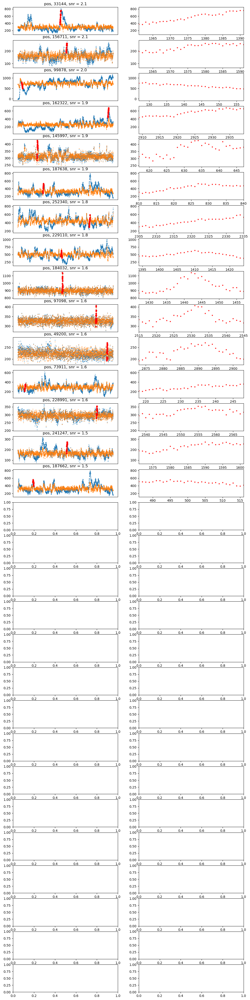

In [170]:
# df = concat2.sort_values('diff_brightening_local', ascending=False).drop(index=droplist) #biggest filt>original
df = df[df['row_from_nn']>50]
df =df.sort_values('snr_local_brightening_filtered2', ascending=False)[:15]
figrows = 30
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    tot, maxols = rff.get_tot_csv(df, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8)
    tot_filt = rff.get_tot_csv_filtered_hap2(df, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8)
    ax[i,0].set_title(str(df.loc[index, "real_type_local"])+", "+str(df.loc[index, "concat_index_copy"])+", snr = "+f"{df.loc[index, 'snr_local_brightening_filtered2']:.1f}")
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.8, c='red')
    if str(df.loc[index, "real_type_local"])=='pos':
        xes = np.linspace(df.loc[index, 'central_point_brightening_filtere']-15,df.loc[index, 'central_point_brightening_filtere']+14,30)
        ax[i,1].set_xlim(df.loc[index, 'central_point_brightening_filtere']-15, df.loc[index, 'central_point_brightening_filtere']+15)
        ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_brightening_filtere'])-15:int(df.loc[index, 'central_point_brightening_filtere'])+15],  s=15, alpha=.8, c='red', zorder=10)
    elif str(df.loc[index, "real_type_local"])=='neg':
        ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-15, df.loc[index, 'central_point_dimming_filtere']+15)
        ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-15:int(df.loc[index, 'central_point_dimming_filtere'])+15],  s=15, alpha=.8, c='red', zorder=10)


In [ ]:
moresats = [195365, 291022, 163685, 326045, 272956, 306621, 22579, 
            79095
,262472
293337
298575
154765,
181844
272947
329013
176927
192302
179370
52316
131777
117765
82320
224886
131780

/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)
/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)


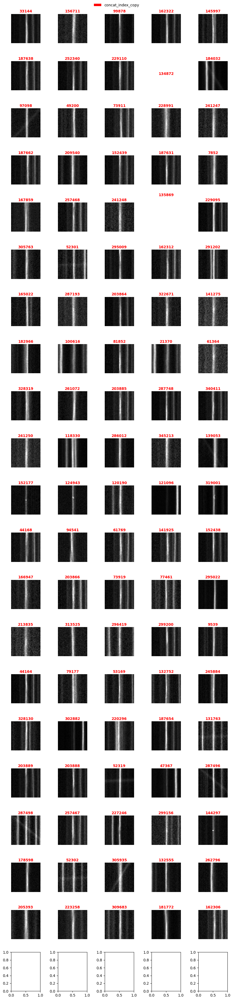

In [155]:
rff.inspect_df_w_stamp_color(nosats.sort_values('snr_local_brightening_filtered2', ascending=False)[:100], titlecol=['concat_index_copy'], imgsize=20)